# Curvilinear grids: waves under topography

On a `Grid` the nodes form a box, so a surface that is not flat, such as topography, can only be approximated by a staircase of cells, and the waves that reflect off it pick up the error of the staircase. A `CurvilinearGrid` bends the grid instead, so that the surface is a row of nodes.

This tutorial simulates an acoustic shot over a hill with a free surface that follows the topography. Along the way it shows how a `CurvilinearGrid` is defined, how derivatives, sparse functions and models work on it, how the free surface and its adjoint are imposed, and how accurate the result is against an analytic solution.

**Notation.** $x$ and $z$ are the physical coordinates, in metres, with $z$ the depth, positive down as everywhere in Devito. The grid is still indexed by integer nodes along each axis, as a `Grid`; the uniformly spaced coordinates of these nodes are the *computational* coordinates $\xi$ (lateral) and $\eta$ (vertical), which the grid `Dimension`s index. A *map* places each computational node $(\xi, \eta)$ at a physical position $(x, z)$. In 2D Devito names the vertical `Dimension` `y`, so below `y` is the vertical grid `Dimension` and `u.dy` the vertical derivative.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from devito import (CurvilinearGrid, CurvilinearMap, Eq, Function, Grid, Inc, Operator,
                    SparseTimeFunction, SubDomain, TensorTimeFunction,
                    TerrainFollowing, TimeFunction, VectorTimeFunction, div, grad,
                    resample)

## 1. The grid

### The topography

The topography is a hill 150 m high, centred at $x = 1.5$ km on a 3 km line, given as topography usually is: as an elevation above a datum, positive up.

In [2]:
def elevation(x):
    return 150.*np.exp(-((x - 1500.)/400.)**2)

### The terrain-following map

`TerrainFollowing` keeps the lateral coordinate, $x = \xi$, and spreads the nodes of each column evenly between the surface, at depth $s(x)$, and a flat bottom at depth $b$:

$$
z(\xi, \eta) = s(\xi) + \eta\,\frac{b - s(\xi)}{b}.
$$

The row at computational depth $\eta = 0$ is the surface, and the last row of the grid, at $\eta = b$, is the flat bottom $z = b$. The relief of the surface fades out linearly with depth, and over a flat surface at $s = 0$ the map is the identity.

Depths are positive down, so the surface is the negative of the elevation, `surface=-elevation`. It can be a function of $x$, as here, or an array with one value per lateral node.

### Rows above the surface

The free surface (section 4) mirrors the wavefield into rows *above* the surface, which must therefore be part of the grid. They are added by extending the grid upwards with a negative vertical `origin`: the map places them at $\eta < 0$, above the surface. The wave equation uses stencils that reach 4 rows, so the grid gets 4 rows above the surface.

The grid below has 301 by 151 nodes from the surface down, over 3000 m by 1500 m, so its spacing is 10 m, plus the 4 rows above. Apart from `mapping`, the arguments are those of a `Grid`.

In [3]:
above = 4  # rows above the surface
mapping = TerrainFollowing(surface=lambda x: -elevation(x))
grid = CurvilinearGrid(shape=(301, 151 + above), extent=(3000., 1500. + 10.*above),
                       origin=(0., -10.*above), mapping=mapping)
x, y = grid.dimensions

print(f'Dimensions {grid.dimensions}, shape {grid.shape}, '
      f'spacing {float(grid.spacing[0]):.0f} m')

Dimensions (x, y), shape (301, 155), spacing 10 m


`grid.coordinates` holds the physical coordinates $x$ and $z$ of every node, as two `Function`s. Drawn in physical space, every fifth grid line shows the columns stretched between the hill and the flat bottom: the rows follow the hill near the surface and flatten with depth. The plots of this notebook show the grid from the surface down.

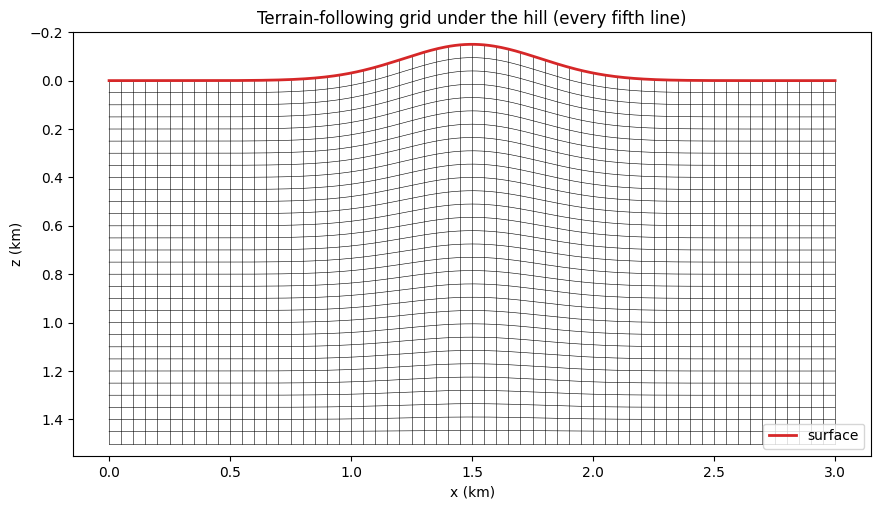

In [4]:
# NBVAL_IGNORE_OUTPUT
below = (slice(None), slice(above, None))  # from the surface down
x_coord, z_coord = (c.data[below]/1000 for c in grid.coordinates)


def plot_grid_lines(ax, step=5):
    ax.plot(x_coord[::step, :].T, z_coord[::step, :].T, 'k', lw=.4)
    ax.plot(x_coord[:, ::step], z_coord[:, ::step], 'k', lw=.4)


fig, ax = plt.subplots(figsize=(12, 5.5))
plot_grid_lines(ax)
ax.plot(x_coord[:, 0], z_coord[:, 0], 'C3', lw=2, label='surface')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_ylim(1.55, -.2)
ax.set_aspect('equal')
ax.legend(loc='lower right')
ax.set_title('Terrain-following grid under the hill (every fifth line)')
plt.show()

## 2. Derivatives on the grid

### Metric terms and Jacobian

Finite differences are taken along the grid, with respect to $\xi$ and $\eta$, while the wave equation needs derivatives with respect to $x$ and $z$. The chain rule connects them through the *metric terms*, the derivatives of the computational coordinates with respect to the physical ones,

$$
\frac{\partial}{\partial x} = \frac{\partial \xi}{\partial x}\frac{\partial}{\partial \xi} + \frac{\partial \eta}{\partial x}\frac{\partial}{\partial \eta},
\qquad
\frac{\partial}{\partial z} = \frac{\partial \xi}{\partial z}\frac{\partial}{\partial \xi} + \frac{\partial \eta}{\partial z}\frac{\partial}{\partial \eta}.
$$

The grid also provides the *Jacobian* $J = \det\left(\partial(x, z)/\partial(\xi, \eta)\right)$, the area of a physical cell over that of a computational cell. For the terrain-following map they have closed forms,

$$
\frac{\partial \xi}{\partial x} = 1, \qquad
\frac{\partial \xi}{\partial z} = 0, \qquad
\frac{\partial \eta}{\partial x} = s'(x)\,\frac{\eta - b}{b - s(x)}, \qquad
\frac{\partial \eta}{\partial z} = \frac{b}{b - s(x)}, \qquad
J = \frac{b - s(x)}{b}.
$$

`grid.metrics` is a dictionary keyed by (physical `Dimension`, computational `Dimension`). Entries that vary in space are `Function`s named after the computational coordinate and the physical axis, so `eta_x` is $\partial\eta/\partial x$; entries that are constant by construction stay numbers. `grid.jacobian` is $J$.

In [5]:
grid.metrics

{(x, x): 1, (y, x): 0, (x, y): eta_x(x, y), (y, y): eta_y(x, y)}

The slope term $\partial\eta/\partial x$ is largest on the flanks of the hill and fades with depth, and $J$ is above one under the hill, where each column spans a longer physical height.

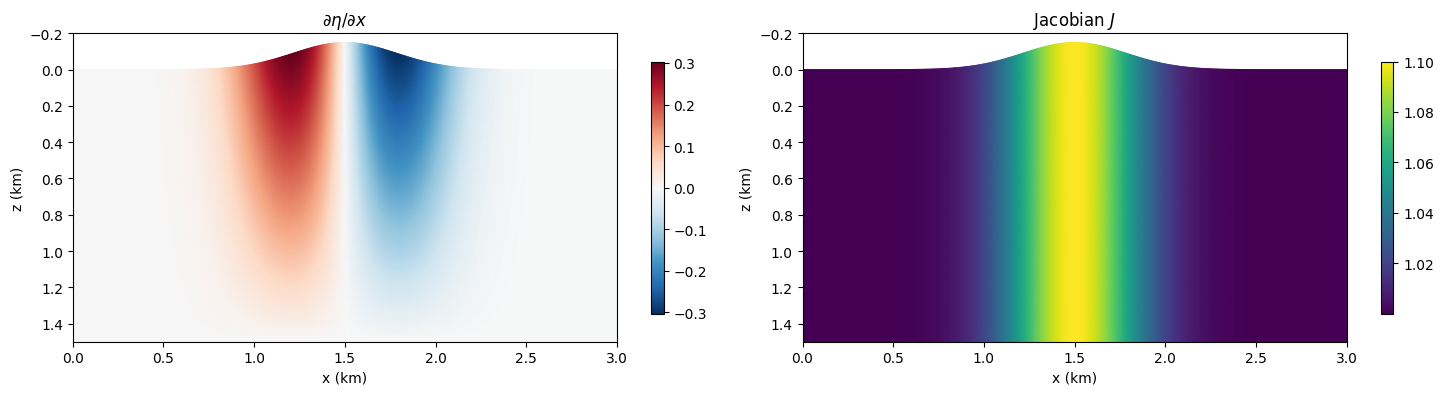

In [6]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
panels = [(grid.metrics[(x, y)].data[below], r'$\partial\eta/\partial x$', 'RdBu_r'),
          (grid.jacobian.data[below], 'Jacobian $J$', 'viridis')]
for ax, (values, title, cmap) in zip(axes, panels, strict=True):
    image = ax.pcolormesh(x_coord, z_coord, values, cmap=cmap, shading='gouraud')
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_xlabel('x (km)')
    ax.set_ylabel('z (km)')
    ax.set_title(title)
    fig.colorbar(image, ax=ax, shrink=.6)
plt.tight_layout()
plt.show()

### Physical derivatives

On a `CurvilinearGrid`, `u.dx` and `u.dy` are the derivatives with respect to the physical $x$ and $z$: Devito applies the chain rule when the derivative is evaluated. It shows in the stencil of a low-order derivative, a difference along the grid $x$ axis plus a difference along the grid $y$ axis multiplied by the metric term `eta_x`:

In [7]:
u = Function(name='u', grid=grid, space_order=2)
u.dx.evaluate

-u(x, y)/h_x + u(x + h_x, y)/h_x + (-0.5*u(x, y - h_y)/h_y + 0.5*u(x, y + h_y)/h_y)*eta_x(x, y)

The derivative along the grid axis, ignoring the map, is written `u.dx(computational=True)`.

A simple check of the physical derivatives is to differentiate the physical depth $z$ itself: $\partial z/\partial x$ must vanish and $\partial z/\partial z$ must be one everywhere, although $z$ varies along the grid rows.

In [8]:
# NBVAL_IGNORE_OUTPUT
depth = Function(name='depth', grid=grid, space_order=8)
dzdx = Function(name='dzdx', grid=grid, space_order=8)
dzdz = Function(name='dzdz', grid=grid, space_order=8)
depth.data_with_halo[:] = grid.coordinates[1].data_with_halo

summary = Operator([Eq(dzdx, depth.dx), Eq(dzdz, depth.dy)]).apply()

NUMA domain count autodetection failed, assuming 1


Operator `Kernel` ran in 0.01 s


In [9]:
interior = (slice(4, -4), slice(4, -4))
print(f'max |dz/dx|     = {np.abs(dzdx.data[interior]).max():.1e}')
print(f'max |dz/dz - 1| = {np.abs(dzdz.data[interior] - 1).max():.1e}')

max |dz/dx|     = 1.1e-05
max |dz/dz - 1| = 1.0e-05


### Nested derivatives and the Laplacian

A derivative of a derivative, such as $\partial_x(b\,\partial_x u)$ for a variable density, is where the curvilinear grid differs from a plain application of the chain rule. Devito evaluates the inner derivative with the chain rule, and the outer one in *conservation form*,

$$
\frac{\partial f}{\partial x} = \frac{1}{J}\left[\frac{\partial}{\partial \xi}\left(J\,\frac{\partial \xi}{\partial x}\,f\right) + \frac{\partial}{\partial \eta}\left(J\,\frac{\partial \eta}{\partial x}\,f\right)\right],
$$

which is equal to the chain rule by the metric identities. Paired this way, the outer derivative is minus the adjoint of the inner one in the inner product weighted by the Jacobian, $\langle f, g\rangle_J = \sum J f g$, exactly as the pair of staggered derivatives of a Cartesian `Grid` are: nested operators such as $\nabla\cdot(b\nabla u)$ are then symmetric in that inner product, and a wave equation built with them is self-adjoint. Over a flat surface both forms are the stencils of a `Grid`. The same pairing applies to a derivative that brings a staggered field back to the nodes, so that `div` and `grad` of a staggered velocity-stress system are adjoint.

The wave equation below therefore uses the Laplacian as the divergence of the gradient, each staggered half a cell, `div(grad(u, shift=.5), shift=-.5)`, which is the symmetric operator, rather than `u.laplace`, which expands into second derivatives of the chain rule. The two agree to the order of the stencils, but only the first has an exact adjoint (section 6).

## 3. The velocity model

Velocity models are usually given on a Cartesian grid. Here the model goes from 1500 m/s above a dipping interface, at a depth of 500 m under the hill, to 2500 m/s below it. It is defined on a `Grid` that extends from 300 m above the datum to the bottom, so that it covers the hill. The interface is smoothed over a few tens of metres: a sharp step in velocity would scatter grid-scale artefacts into the wavefield, on any grid.

In [10]:
model_grid = Grid(shape=(301, 181), extent=(3000., 1800.), origin=(0., -300.))
x_model = np.linspace(0., 3000., 301)[:, None]
z_model = np.linspace(-300., 1500., 181)[None, :]
cartesian_velocity = Function(name='cartesian_velocity', grid=model_grid)
interface_depth = 500. + .1*(x_model - 1500.)
cartesian_velocity.data[:] = 2000. + 500.*np.tanh((z_model - interface_depth)/30.)

`resample(f, cartesian)` sets a `Function` on the curvilinear grid to the Cartesian `Function` interpolated at the physical position of each node, which for this map is an interpolation along each column. `resample(f, cartesian, transpose=True)` applies its exact transpose, which brings a gradient computed on the curvilinear grid back to the Cartesian model in an inversion.

In [11]:
velocity = Function(name='velocity', grid=grid, space_order=8)
resample(velocity, cartesian_velocity)
print(f'velocity between {velocity.data.min():.0f} and {velocity.data.max():.0f} m/s')

velocity between 1500 and 2500 m/s


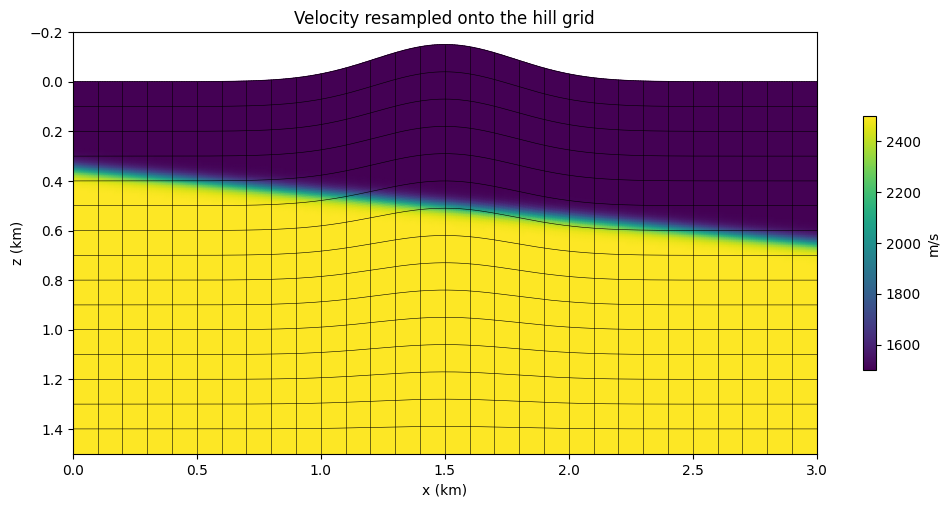

In [12]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 5.5))
image = ax.pcolormesh(x_coord, z_coord, velocity.data[below], cmap='viridis',
                      shading='gouraud')
plot_grid_lines(ax, step=10)
ax.set_ylim(1.5, -.2)
ax.set_aspect('equal')
ax.set_xlabel('x (km)')
ax.set_ylabel('z (km)')
ax.set_title('Velocity resampled onto the hill grid')
fig.colorbar(image, ax=ax, shrink=.6, label='m/s')
plt.show()

## 4. Sources, receivers and the free surface

### Sparse functions

The coordinates of sparse functions on a `CurvilinearGrid` are physical, so the source and the receivers are placed exactly as on a `Grid`: the source 20 m below the top of the hill, and a line of 201 receivers 10 m below the surface from $x = 0.5$ km to 2.5 km. Devito maps them onto the grid with the inverse of the map every time an `Operator` runs, so they can be moved between runs.

Interpolation at the receivers works as on a `Grid`. Injection works as on a `Grid` too, and, as on a `Grid`, does not scale the source by the volume of the cells it is spread over. To inject a point source in physical space whatever the stretching of the cells around it, the injected expression is divided by the Jacobian, `expr=src/grid.jacobian`, which injection reads at each node the source is spread over: with $P$ the interpolation, injection is $J^{-1}P^\top$, the transpose of the interpolation in the inner product weighted by $J$,

$$
\langle P u, d\rangle = \sum_{\mathrm{nodes}} J\, u\, \left(J^{-1}P^\top d\right).
$$

The time step uses `grid.min_spacing`, the smallest physical distance between neighbouring nodes, in place of the grid spacing: $\Delta t = 0.1\,h_{\min}/v_{\max}$, small compared with the stability limit, for the accuracy discussed in section 9.

In [13]:
f0, t0, tn = 10., .12, 1.2  # peak frequency (Hz), wavelet delay and duration (s)
dt = float(.1*grid.min_spacing/velocity.data.max())
nt = int(np.ceil(tn/dt)) + 1
time_values = np.arange(nt)*dt


def ricker(t):
    a = (np.pi*f0*(t - t0))**2
    return (1 - 2*a)*np.exp(-a)


source_position = np.array([[1500., -elevation(1500.) + 20.]])
receiver_x = np.linspace(500., 2500., 201)
receiver_positions = np.stack([receiver_x, -elevation(receiver_x) + 10.], axis=1)

src = SparseTimeFunction(name='src', grid=grid, npoint=1, nt=nt,
                         coordinates=source_position)
src.data[:, 0] = ricker(time_values)
rec = SparseTimeFunction(name='rec', grid=grid, npoint=201, nt=nt,
                         coordinates=receiver_positions)
print(f'{nt} time steps of {1000*dt:.3f} ms')

3002 time steps of 0.400 ms


### The free surface

The pressure vanishes on the surface. On a `Grid` this is imposed with an odd mirror: the surface row $s$ is set to zero, and each row $z$ above it to minus the row as far below it, $u(z) = -u(2s - z)$. The free surface is written the same way on a `CurvilinearGrid`, as equations after each update of `u`, over `SubDomain`s of the surface row and of the `above` rows above it.

Under a slope, the grid columns are not normal to the surface, and a mirror along the columns would only be second-order accurate. On a `CurvilinearGrid`, a read at the mirror point of the written point through a row of the grid is therefore the read at the *image* $p^\star$ of the written point $p$, its mirror through the closest point $f$ of the surface, normal to it,

$$
u(p) = -u(p^\star), \qquad p^\star = 2f - p,
$$

with $u(p^\star)$ interpolated with Lagrange polynomials, with as many points along each axis as the space order of `u`, from the nodes at or below the surface. Over a plane surface this is the exact image of the wavefield, so the free surface is imposed to the order of the stencils; over a flat surface it is the usual odd mirror. The interpolation weights only depend on the grid, and are computed once, when the `Operator` is built.

The equations only write the surface row and the rows above it, which are part of the grid: the halo is never touched. Written over `SubDomain`s, they also run with MPI as they are, whichever ranks hold the surface (a constant row index, `u.subs(y, s)`, would be a local index on each rank).

In [14]:
u = TimeFunction(name='u', grid=grid, space_order=8, time_order=2)
m = Function(name='m', grid=grid, space_order=8)
m.data[:] = 1/velocity.data**2


class Rows(SubDomain):
    """`thickness` rows of a grid from the row `start`, across the grid."""

    def __init__(self, start, thickness, grid):
        self.name = f'rows_{start}_{thickness}'
        self.start, self.thickness = start, thickness
        super().__init__(grid=grid)

    def define(self, dimensions):
        *lateral, vertical = dimensions
        after = self.grid.shape[-1] - self.start - self.thickness
        return {**{d: d for d in lateral}, vertical: ('middle', self.start, after)}


def free_surface(field):
    """Zero `field` on the surface row and mirror it, odd, into the rows above."""
    grid = field.function.grid
    vertical = grid.dimensions[-1]
    return [Eq(field, 0, subdomain=Rows(above, 1, grid)),
            Eq(field, -field.subs(vertical, 2*above - vertical),
               subdomain=Rows(0, above, grid))]


surface = free_surface(u.forward)
surface

[Eq(u(t + dt, x, y), 0), Eq(u(t + dt, x, y), -u(t + dt, x, 8 - y))]

## 5. The simulation

The acoustic wave equation

$$
m\,\frac{\partial^2 u}{\partial t^2} - \nabla\cdot\nabla u = s, \qquad m = \frac{1}{v^2},
$$

is discretized with the leapfrog scheme and written as it would be on a `Grid`, with the symmetric Laplacian of section 2. The update runs over the whole grid, and the free surface then overwrites the rows above the surface.

In [15]:
laplacian = div(grad(u, shift=.5), shift=-.5)
update = Eq(u.forward, 2*u - u.backward + dt**2*laplacian/m)
op = Operator([update] + surface +
              src.inject(field=u.forward, expr=src*dt**2/(m*grid.jacobian)) +
              rec.interpolate(expr=u))

We run the operator in segments, to keep snapshots of the wavefield at 0.3 s, 0.55 s and 0.8 s.

In [16]:
# NBVAL_IGNORE_OUTPUT
snapshots = []
start = 0
for snapshot_time in [.3, .55, .8]:
    step = int(snapshot_time/dt)
    summary = op.apply(dt=dt, time_m=start, time_M=step)
    snapshots.append((snapshot_time, u.data[(step + 1) % 3].copy()))
    start = step + 1
summary = op.apply(dt=dt, time_m=start, time_M=nt - 2)

Operator `Kernel` ran in 13.75 s


Operator `Kernel` ran in 10.94 s


Operator `Kernel` ran in 9.97 s


Operator `Kernel` ran in 16.34 s


Drawn at the physical position of the nodes, the snapshots show the direct wave, its reflection off the hill with the polarity flip of a free surface, and the reflection off the dipping interface (dashed).

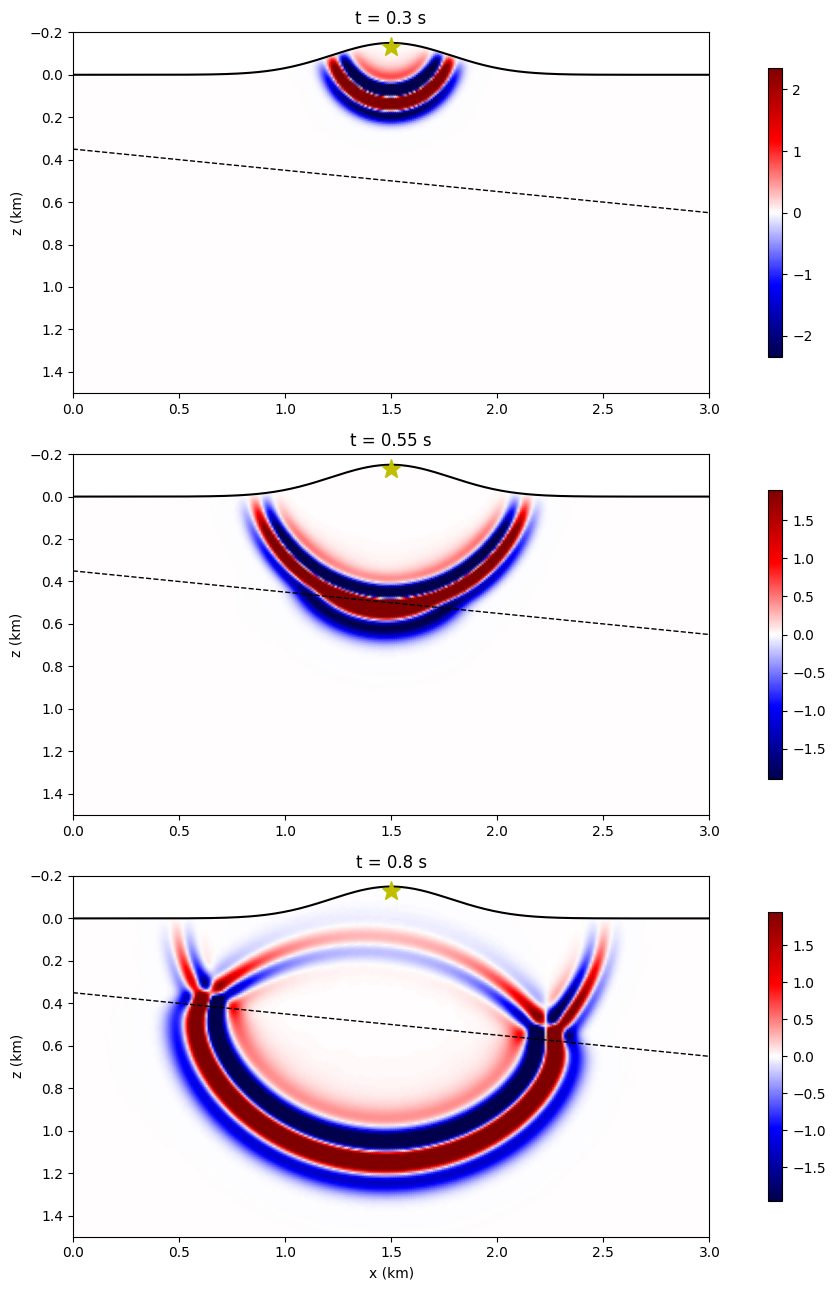

In [17]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(3, 1, figsize=(12, 13))
interface = 500. + .1*(np.linspace(0., 3000., 301) - 1500.)
for ax, (snapshot_time, snapshot) in zip(axes, snapshots, strict=True):
    clip = .3*np.abs(snapshot[below]).max()
    image = ax.pcolormesh(x_coord, z_coord, snapshot[below], cmap='seismic',
                          vmin=-clip, vmax=clip, shading='gouraud')
    ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5)
    ax.plot(np.linspace(0., 3., 301), interface/1000, 'k--', lw=1)
    ax.plot(*(source_position/1000).T, 'y*', ms=14)
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_ylabel('z (km)')
    ax.set_title(f't = {snapshot_time} s')
    fig.colorbar(image, ax=ax, shrink=.8)
axes[-1].set_xlabel('x (km)')
plt.tight_layout()
plt.show()

The shot record shows the same events at the receivers. The receivers are only 10 m below the free surface, where the pressure is close to zero, so the direct wave is strong only next to the source, and the reflection off the interface arrives between 0.9 s and 1.2 s, its shape bent by the hill. The grid has no absorbing boundary, so the record stops at 1.2 s, before the reflections off the sides and the bottom of the grid arrive.

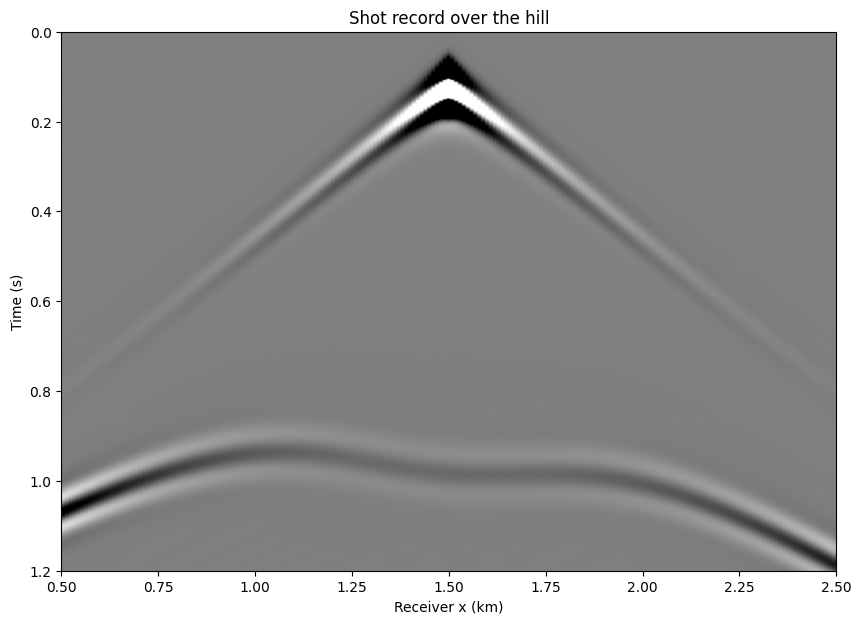

In [18]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(10, 7))
clip = .05*np.abs(rec.data).max()
ax.imshow(rec.data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip,
          extent=[receiver_x[0]/1000, receiver_x[-1]/1000, tn, 0])
ax.set_xlabel('Receiver x (km)')
ax.set_ylabel('Time (s)')
ax.set_title('Shot record over the hill')
plt.show()

## 6. The adjoint

Inversion and imaging need the adjoint of the modelling, which back-propagates data from the receivers. With the symmetric Laplacian and the injected source divided by $J$, the propagation is self-adjoint in the inner product weighted by $J$, except for the free surface: the images $u(p) = -\sum_k W_{pk}\, u(q_k)$ are not symmetric over a curved surface.

Write $L$ for the Laplacian over the whole grid, and $E$ for the extension of the wavefield from the nodes below the surface to the rows above it by the images, so that each update applies $L E$. Its transpose in the inner product weighted by $J$ is

$$
J^{-1} E^\top J\, L,
$$

that is, the adjoint wavefield $v$ is held at zero above the surface, the update runs over the whole grid, rows above the surface included, and the values it leaves there are folded back onto the nodes below with the transposed weights,

$$
v_q \leftarrow v_q - \frac{c_q}{J_q} \sum_{p} W_{pq}\, J_p\, \frac{v_p}{c_p},
$$

with $c$ the factor of the Laplacian in the update, here $\Delta t^2/m$, after which the rows above the surface are zero again. Over a flat surface the fold is the usual odd mirror.

The fold is written as the mirror, with increments: an `Inc` that writes at the mirror point $z$ of the point $2s - z$ it reads, $v(z) \mathrel{+}= \dots v(2s - z)$, is on a `CurvilinearGrid` the transpose of the read at the image, and adds to each node $q$ that interpolates the image of $p$, with its weight $W_{pq}$. The terms at the written point, $c_q/J_q$, are read at each of these nodes.

In [19]:
v = TimeFunction(name='v', grid=grid, space_order=8, time_order=2)
src_adjoint = SparseTimeFunction(name='src_adjoint', grid=grid, npoint=1, nt=nt,
                                 coordinates=source_position)
residual = SparseTimeFunction(name='residual', grid=grid, npoint=201, nt=nt,
                              coordinates=receiver_positions)


def free_surface_adjoint(field, coefficient):
    """
    The transpose of `free_surface` after an update of `field` that leaves
    `coefficient` times the Laplacian in the rows above the surface: these rows
    folded onto the rows below them, then zero.
    """
    grid = field.function.grid
    vertical = grid.dimensions[-1]
    folded = (grid.jacobian*field/coefficient).subs(vertical, 2*above - vertical)
    return [Inc(field, -coefficient/grid.jacobian*folded,
                subdomain=Rows(above + 1, above, grid)),
            Eq(field, 0, subdomain=Rows(0, above + 1, grid))]


update_adjoint = Eq(v.backward,
                    2*v - v.forward + dt**2*div(grad(v, shift=.5), shift=-.5)/m)
op_adjoint = Operator([update_adjoint] +
                      free_surface_adjoint(v.backward, dt**2/m) +
                      residual.inject(field=v.backward, expr=residual*dt**2/(m*grid.jacobian)) +
                      src_adjoint.interpolate(expr=v))

The adjoint is checked with the dot test: for the modelling $F$ from the source wavelet $s$ to the data, and any data $d$,

$$
\langle F s, d\rangle = \langle s, F^\top d\rangle.
$$

We take the shot record above as $F s$, and random data for $d$.

In [20]:
# NBVAL_IGNORE_OUTPUT
residual.data[:] = np.random.default_rng(0).standard_normal(residual.data.shape)
summary = op_adjoint.apply(dt=dt, time_M=nt - 2)

Operator `Kernel` ran in 114.92 s


In [21]:
forward = np.dot(rec.data.ravel(), residual.data.ravel())
adjoint = np.dot(src.data.ravel(), src_adjoint.data.ravel())
print(f'<Fs, d> = {forward:.6e}, <s, F^T d> = {adjoint:.6e}, '
      f'relative difference {abs(forward - adjoint)/abs(forward):.1e}')

<Fs, d> = 1.901942e+02, <s, F^T d> = 1.901909e+02, relative difference 1.7e-05


In [22]:
assert np.isclose(forward, adjoint, rtol=1e-4)

The two agree to the single precision of the computation, accumulated over the 3000 time steps: the adjoint propagation is the exact transpose of the modelling, free surface included.

## 7. Variable density

With a variable density $\rho$, the acoustic wave equation for the pressure $p$ is

$$
\frac{1}{\kappa}\,\frac{\partial^2 p}{\partial t^2} - \nabla\cdot\left(b\,\nabla p\right) = s,
\qquad \kappa = \rho v^2, \qquad b = \frac{1}{\rho},
$$

with $\kappa$ the bulk modulus and $b$ the buoyancy. It is written with the same pairs of staggered derivatives as the Laplacian, one per axis,

$$
\nabla\cdot\left(b\,\nabla p\right) \approx \sum_{d} D^-_{d}\left(b_{d+1/2}\, D^+_{d}\, p\right),
$$

where $D^+_d$ is the derivative along the physical axis $d$ evaluated half a cell after the nodes, $D^-_d$ the derivative that brings it back to the nodes in conservation form, and $b_{d+1/2}$ the buoyancy at the half points where $D^+_d p$ lives. `b.subs(d, d + d.spacing/2)` evaluates $b$ there, by interpolation between the nodes. Writing `div(b*grad(p, shift=.5), shift=-.5)` instead would read $b$ at the nodes, half a cell away from the gradient it multiplies, which makes the operator only first-order accurate. The operator stays symmetric in the inner product weighted by $J$, so the propagation is self-adjoint in the inner product weighted by $J/\kappa$, and its free surface is transposed by `free_surface_adjoint` with the factor of the operator in the update, $\Delta t^2\kappa$.

The density follows the velocity by Gardner's relation, $\rho = 0.31\,v^{1/4}$, in g/cm$^3$ with $v$ in m/s, which gives the interface a density contrast of 14 percent on top of its velocity contrast.

The free surface reads the parameters at the mirror nodes, laterally as far as the stencils of the field, including in the halo at the sides of the grid. Parameters must therefore be defined in their halo too, here by extending their edge values, as `SeismicModel` does.

In [23]:
def div_b_grad(b, p):
    # The staggered pairs of derivatives of div(b grad p), b at the half points
    return sum((b.subs(d, d + d.spacing/2)*p.diff(d)(x0=d + d.spacing/2))
               .diff(d)(x0=d - d.spacing/2) for d in p.grid.dimensions)

In [24]:
def set_with_halo(function, values):
    function.data_with_halo[:] = np.pad(values, function.halo, mode='edge')


rho = .31*velocity.data**.25
kappa = Function(name='kappa', grid=grid, space_order=8)
b = Function(name='b', grid=grid, space_order=8)
set_with_halo(kappa, rho*velocity.data**2)
set_with_halo(b, 1/rho)
print(f'density between {rho.min():.2f} and {rho.max():.2f} g/cm^3')

density between 1.93 and 2.19 g/cm^3


The accuracy of the operator can be checked on the hill grid against its analytic value for smooth fields, $p = \sin(kx)\cos(kz)$ and $b = 1 + \frac{1}{2}\sin(kx + 1)\sin(0.7kz)$ with a wavelength of 400 m, for which $\nabla\cdot(b\nabla p) = b\,\Delta p + \nabla b\cdot\nabla p$. Halving the grid spacing divides the error by four with $b$ at the half points, and only by two with $b$ at the nodes.

In [25]:
def operator_error(spacing, shifted):
    n = int(1000/spacing) + 1
    hill = CurvilinearGrid(shape=(n, n), extent=(1000., 1000.), dtype=np.float64,
                           mapping=TerrainFollowing(
                               lambda x: -100.*np.exp(-((x - 500.)/200.)**2)))
    k = 2*np.pi/400.
    pad = 8
    xc, zc = (np.pad(c.data, pad, mode='reflect', reflect_type='odd')
              for c in hill.coordinates)
    pc = Function(name='pc', grid=hill, space_order=8)
    bc = Function(name='bc', grid=hill, space_order=8)
    pc.data_with_halo[:] = np.sin(k*xc)*np.cos(k*zc)
    bc.data_with_halo[:] = 1 + .5*np.sin(k*xc + 1.)*np.sin(.7*k*zc)
    gradient = (k*np.cos(k*xc)*np.cos(k*zc), -k*np.sin(k*xc)*np.sin(k*zc))
    gradient_b = (.5*k*np.cos(k*xc + 1.)*np.sin(.7*k*zc),
                  .35*k*np.sin(k*xc + 1.)*np.cos(.7*k*zc))
    exact = (bc.data_with_halo*(-2*k**2)*pc.data_with_halo +
             sum(a*b for a, b in zip(gradient, gradient_b, strict=True)))
    exact = exact[pad:-pad, pad:-pad]
    result = Function(name='result', grid=hill, space_order=8)
    expr = div_b_grad(bc, pc) if shifted else div(bc*grad(pc, shift=.5), shift=-.5)
    Operator(Eq(result, expr)).apply()
    inner = (slice(10, -10), slice(10, -10))
    return np.abs(result.data[inner] - exact[inner]).max()/np.abs(exact[inner]).max()

In [26]:
# NBVAL_IGNORE_OUTPUT
errors = {shifted: [operator_error(h, shifted) for h in (10., 5.)]
          for shifted in (True, False)}
for shifted, (coarse, fine) in errors.items():
    name = 'b at the half points' if shifted else 'b at the nodes'
    print(f'{name:21s}: error {coarse:.1e} at 10 m, {fine:.1e} at 5 m, '
          f'order {np.log2(coarse/fine):.1f}')

Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


Operator `Kernel` ran in 0.01 s


b at the half points : error 8.0e-04 at 10 m, 2.0e-04 at 5 m, order 2.0
b at the nodes       : error 1.5e-02 at 10 m, 7.6e-03 at 5 m, order 1.0


In [27]:
assert np.log2(errors[True][0]/errors[True][1]) > 1.8

The update and the source carry $\Delta t^2\kappa$ where the constant-density case had $\Delta t^2/m$; with a constant density both are the same equation.

In [28]:
# NBVAL_IGNORE_OUTPUT
p = TimeFunction(name='p', grid=grid, space_order=8, time_order=2)
rec_density = SparseTimeFunction(name='rec_density', grid=grid, npoint=201, nt=nt,
                                 coordinates=receiver_positions)

coefficient = dt**2*kappa
update_density = Eq(p.forward, 2*p - p.backward +
                    coefficient*div_b_grad(b, p))
op_density = Operator([update_density] + free_surface(p.forward) +
                      src.inject(field=p.forward, expr=src*coefficient/grid.jacobian) +
                      rec_density.interpolate(expr=p))
summary = op_density.apply(dt=dt, time_M=nt - 2)

Operator `Kernel` ran in 57.87 s


Divided by the density above the interface, the direct wave and the free-surface reflections of the variable-density record are those of the constant-density one: in the pressure formulation, a constant density only scales the field. The reflection off the interface is stronger, as its reflection coefficient depends on the contrast of impedance $\rho v$ rather than of velocity alone: at normal incidence

$$
R = \frac{\rho_2 v_2 - \rho_1 v_1}{\rho_2 v_2 + \rho_1 v_1},
$$

which is 0.25 with a constant density and 0.31 with this one, a ratio of 1.23. The reflection recorded above the source, off an interface that dips by 6 degrees, gives a ratio close to it.

In [29]:
early = time_values < .5
rho_above = .31*1500**.25
ratio = np.abs(rec_density.data[early]).max()/np.abs(rec.data[early]).max()
print(f'direct wave amplitude ratio {ratio:.3f}, density above the interface '
      f'{rho_above:.3f}')

late = time_values > .85
centre = np.argmin(np.abs(receiver_x - 1500.))
reflection = (np.abs(rec_density.data[late, centre]).max()/rho_above /
              np.abs(rec.data[late, centre]).max())
impedance = [(.31*v**.25*v) for v in (1500., 2500.)]
predicted = ((impedance[1] - impedance[0])/(impedance[1] + impedance[0]))/.25
print(f'interface reflection ratio {reflection:.3f}, normal incidence {predicted:.3f}')

direct wave amplitude ratio 1.929, density above the interface 1.929
interface reflection ratio 1.245, normal incidence 1.235


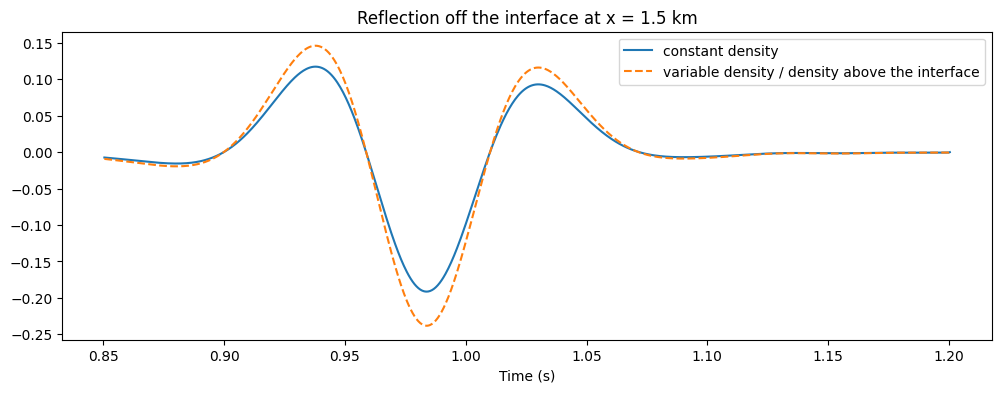

In [30]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(time_values[late], rec.data[late, centre], label='constant density')
ax.plot(time_values[late], rec_density.data[late, centre]/rho_above, '--',
        label='variable density / density above the interface')
ax.set_xlabel('Time (s)')
ax.set_title('Reflection off the interface at x = 1.5 km')
ax.legend()
plt.show()

The adjoint is the same equation run backward in time, followed by `free_surface_adjoint(q.backward, coefficient)`, and passes the dot test to single precision (in double precision, the same propagation on a smaller hill agrees to $4\times10^{-9}$).

In [31]:
# NBVAL_IGNORE_OUTPUT
q = TimeFunction(name='q', grid=grid, space_order=8, time_order=2)
update_density_adjoint = Eq(q.backward, 2*q - q.forward +
                            coefficient*div_b_grad(b, q))
op_density_adjoint = Operator([update_density_adjoint] +
                              free_surface_adjoint(q.backward, coefficient) +
                              residual.inject(field=q.backward,
                                              expr=residual*coefficient/grid.jacobian) +
                              src_adjoint.interpolate(expr=q))
summary = op_density_adjoint.apply(dt=dt, time_M=nt - 2)

Operator `Kernel` ran in 108.83 s


In [32]:
forward = np.dot(rec_density.data.ravel(), residual.data.ravel())
adjoint = np.dot(src.data.ravel(), src_adjoint.data.ravel())
print(f'<Fs, d> = {forward:.6e}, <s, F^T d> = {adjoint:.6e}, '
      f'relative difference {abs(forward - adjoint)/abs(forward):.1e}')

<Fs, d> = 3.672314e+02, <s, F^T d> = 3.672359e+02, relative difference 1.2e-05


In [33]:
assert np.isclose(forward, adjoint, rtol=1e-4)

## 8. Elastic waves

### The equations and the traction-free surface

In an isotropic elastic medium, the particle velocity $\mathbf{v}$ and the stress tensor $\boldsymbol{\tau}$ obey

$$
\rho\,\frac{\partial \mathbf{v}}{\partial t} = \nabla\cdot\boldsymbol{\tau},
\qquad
\frac{\partial \boldsymbol{\tau}}{\partial t} = \lambda\,(\nabla\cdot\mathbf{v})\,I + \mu\left(\nabla\mathbf{v} + \nabla\mathbf{v}^\top\right),
$$

with $\lambda$ and $\mu$ the Lamé parameters, and the free surface is traction-free: $\boldsymbol{\tau}\cdot\mathbf{n} = 0$, with $\mathbf{n}$ the normal to the surface.

The mirror of sections 4 and 6 does not carry over. An odd mirror is exact for the pressure because the wave equation makes its second normal derivative vanish on the surface, where $p = 0$; the normal and shear stresses on a traction-free surface have no such property, and mirroring the stress, the stress imaging of Levander (1988) and its curvilinear extensions, does not preserve the accuracy of the scheme at the surface (see the review in O'Reilly et al., 2021). On curvilinear grids, the method of O'Reilly et al. (2021, *A high-order finite-difference method on staggered curvilinear grids for seismic wave propagation applications with topography*, BSSA) instead uses summation-by-parts (SBP) operators: along the vertical axis, the staggered derivatives and interpolations are replaced by operators of O'Reilly and Petersson (2020) with one-sided boundary closures, and the fields that are staggered vertically get a point on the surface. These operators mimic integration by parts,

$$
\sum H_{-}\, \sigma\, D_{-} v = -\sum H_{+}\, v\, D_{+}\sigma - v_0\,\sigma_0,
$$

with $H_\pm$ the quadrature weights of the two staggered grids and $v_0\,\sigma_0$ the product on the surface, as $\int_0^\infty \sigma\,v' = -\int_0^\infty v\,\sigma' - v(0)\,\sigma(0)$, so that the discrete elastic energy changes only through the surface terms. The momentum equation is taken in conservation form,

$$
\rho\,\frac{\partial v_i}{\partial t} = \frac{1}{J}\sum_k \frac{\partial}{\partial \xi_k}\left(J\,\frac{\partial \xi_k}{\partial x_j}\,\tau_{ij}\right),
$$

where the vertical flux $J\,\nabla\eta\cdot\boldsymbol{\tau}$ on the surface is the traction. The traction-free condition is imposed weakly by dropping it from the vertical derivative, $\tilde D_+ = D_+ - H_+^{-1}B$, which cancels the surface term: the discrete energy is conserved exactly, so the scheme is stable over any smooth topography, accurate to fourth order in the interior and second order at the surface, and its adjoint is its exact transpose.

Like the acoustic free surface, this is an equation definition rather than a property of the grid. The seismic examples define it in `examples.seismic.elastic`: `traction_free_update(v, tau, buoyancy, lam, mu)` returns the equations of one time step of this scheme, written with the SBP coefficients of `examples.seismic.elastic.sbp` and the metric terms of the grid at the staggered points, `grid.staggered_terms`: the velocity updates, then the stress updates, with one equation per row of the boundary closures and one for the rows below. The fields have space order 4 and time order 1; the vertical fields keep their surface point in the row above the surface. Sources are injected into the stress after the updates.

### Over the hill

The elastic model has the P velocity of section 3, an S velocity $v_s = v_p/\sqrt{3}$ and the density of section 7. The shear waves are slower, so their shortest wavelength is shorter: with a peak frequency of 5 Hz they are sampled by about 7 points per wavelength on the 10 m grid. The source is an explosion, injected in the normal stresses, at the same place as the acoustic source.

In [34]:
from examples.seismic.elastic import traction_free_update

v_el = VectorTimeFunction(name='v_el', grid=grid, space_order=4, time_order=1)
tau_el = TensorTimeFunction(name='tau_el', grid=grid, space_order=4, time_order=1)
vp_el = velocity.data
vs_el = vp_el/np.sqrt(3)
rho_el = .31*vp_el**.25
buoyancy_el, lam_el, mu_el = (Function(name=name, grid=grid, space_order=4)
                              for name in ('buoyancy_el', 'lam_el', 'mu_el'))
set_with_halo(buoyancy_el, 1/rho_el)
set_with_halo(lam_el, rho_el*(vp_el**2 - 2*vs_el**2))
set_with_halo(mu_el, rho_el*vs_el**2)

f0_el = 5.
dt_el = float(.25*grid.min_spacing/vp_el.max())
nt_el = int(np.ceil(tn/dt_el)) + 1
time_el = np.arange(nt_el)*dt_el
a_el = (np.pi*f0_el*(time_el - .25))**2
src_el = SparseTimeFunction(name='src_el', grid=grid, npoint=1, nt=nt_el,
                            coordinates=source_position)
src_el.data[:, 0] = (1 - 2*a_el)*np.exp(-a_el)
rec_el = SparseTimeFunction(name='rec_el', grid=grid, npoint=201, nt=nt_el,
                            coordinates=receiver_positions)

op_el = Operator(traction_free_update(v_el, tau_el, buoyancy_el, lam_el, mu_el) +
                 src_el.inject(field=tau_el.forward[0, 0], expr=src_el*dt_el/grid.jacobian) +
                 src_el.inject(field=tau_el.forward[1, 1], expr=src_el*dt_el/grid.jacobian) +
                 rec_el.interpolate(expr=v_el[1]))
print(f'{nt_el} time steps of {1000*dt_el:.3f} ms')

Operator `sbp_terms` ran in 0.01 s


Operator `sbp_terms` ran in 0.01 s


1201 time steps of 1.000 ms


In [35]:
# NBVAL_IGNORE_OUTPUT
snapshots_el = []
start = 0
for snapshot_time in [.45, .7, .95]:
    step = int(snapshot_time/dt_el)
    summary = op_el.apply(dt=dt_el, time_m=start, time_M=step)
    snapshots_el.append((snapshot_time, np.array(v_el[1].data[(step + 1) % 2])))
    start = step + 1
summary = op_el.apply(dt=dt_el, time_m=start, time_M=nt_el - 2)

Operator `Kernel` ran in 0.78 s


Operator `Kernel` ran in 0.39 s


Operator `Kernel` ran in 0.40 s


Operator `Kernel` ran in 0.42 s


The vertical velocity shows the P wave, then the slower S wave, converted from the P wave at the surface and at the interface, and a Rayleigh wave travelling along the surface of the hill, its amplitude decaying with depth.

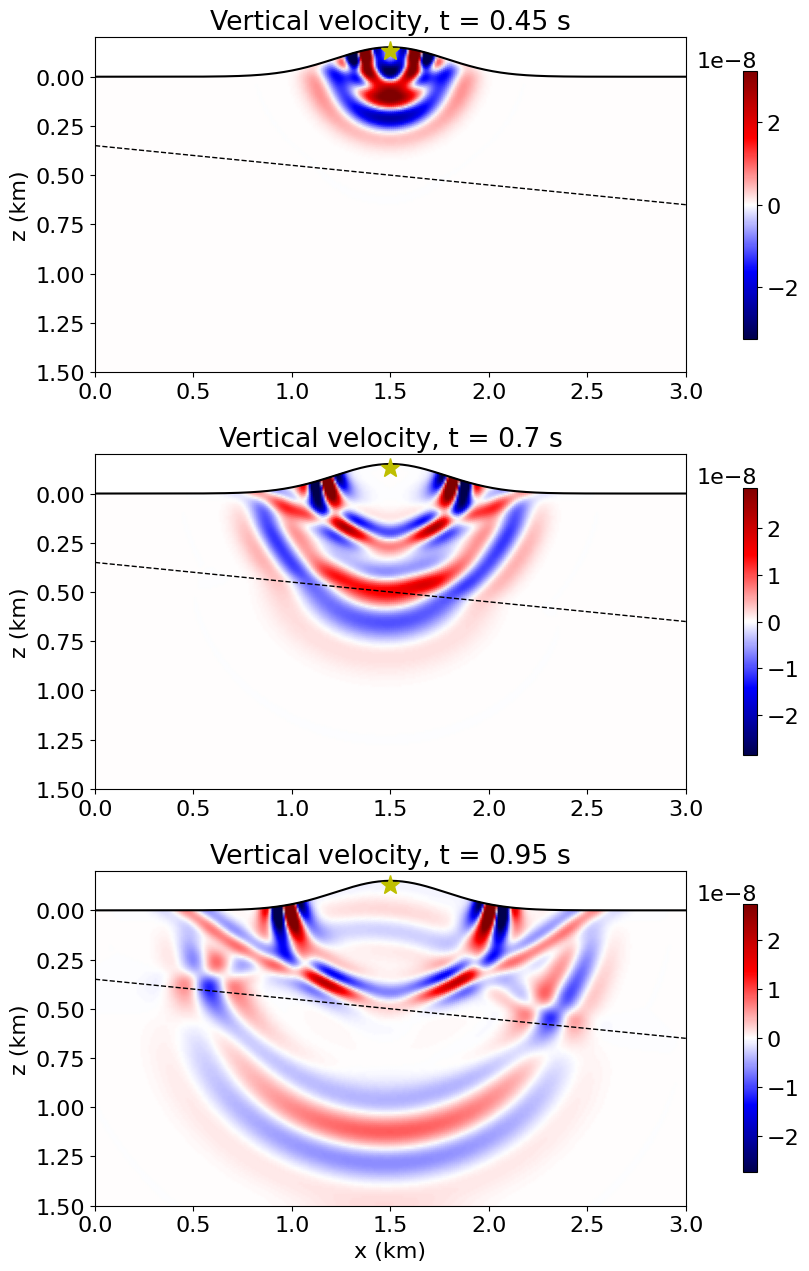

In [36]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(3, 1, figsize=(12, 13))
for ax, (snapshot_time, snapshot) in zip(axes, snapshots_el, strict=True):
    clip = .3*np.abs(snapshot[below]).max()
    image = ax.pcolormesh(x_coord, z_coord, snapshot[below], cmap='seismic',
                          vmin=-clip, vmax=clip, shading='gouraud')
    ax.plot(x_coord[:, 0], z_coord[:, 0], 'k', lw=1.5)
    ax.plot(np.linspace(0., 3., 301), interface/1000, 'k--', lw=1)
    ax.plot(*(source_position/1000).T, 'y*', ms=14)
    ax.set_ylim(1.5, -.2)
    ax.set_aspect('equal')
    ax.set_ylabel('z (km)')
    ax.set_title(f'Vertical velocity, t = {snapshot_time} s')
    fig.colorbar(image, ax=ax, shrink=.8)
axes[-1].set_xlabel('x (km)')
plt.tight_layout()
plt.show()

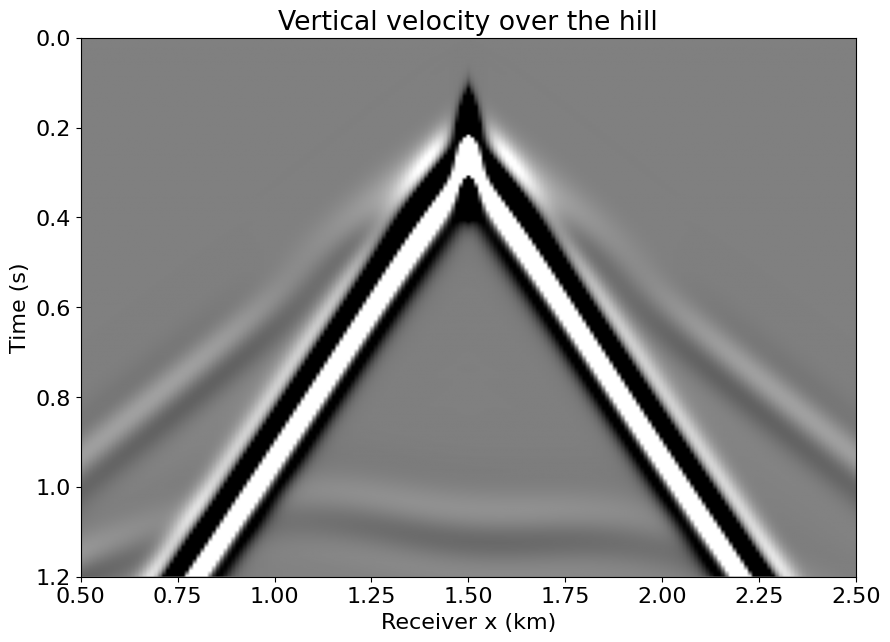

In [37]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(10, 7))
clip = .05*np.abs(rec_el.data).max()
ax.imshow(rec_el.data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip,
          extent=[receiver_x[0]/1000, receiver_x[-1]/1000, tn, 0])
ax.set_xlabel('Receiver x (km)')
ax.set_ylabel('Time (s)')
ax.set_title('Vertical velocity over the hill')
plt.show()

At the receivers, 10 m below the surface, the record is dominated by the Rayleigh wave, slower than the P wave and much stronger; the reflection off the interface arrives around 1.1 s.

### Accuracy on a tilted plane

As for the acoustic free surface, a plane gives a reference: under a plane tilted by a slope of 0.1, with the source 150 m below it and the receivers 20 m below it, the velocities in the frame of the plane, tangential and normal, must be those under a flat surface with the same geometry relative to it. The function below runs both on a 1.5 km by 0.75 km grid and returns their relative difference.

In [38]:
def elastic_plane(slope, spacing, vp=2000., vs=1150., rho=2.):
    plane = CurvilinearGrid(shape=(int(1500/spacing) + 1, int(750/spacing) + 2),
                            extent=(1500., 750. + spacing), origin=(0., -spacing),
                            mapping=TerrainFollowing(lambda x: slope*x),
                            dtype=np.float64)
    vp_ = VectorTimeFunction(name='vp_', grid=plane, space_order=4, time_order=1)
    tp_ = TensorTimeFunction(name='tp_', grid=plane, space_order=4, time_order=1)
    dt = .25*spacing*(750. - 1500.*slope)/750./vp
    nt = int(round(.6/dt)) + 1
    tangent = np.array([1., slope])/np.hypot(1., slope)
    normal = np.array([-slope, 1.])/np.hypot(1., slope)
    centre = np.array([750., 750.*slope])
    src = SparseTimeFunction(name='src', grid=plane, npoint=1, nt=nt,
                             coordinates=[centre + 150.*normal])
    a = (np.pi*8.*(dt*np.arange(nt) - .15))**2
    src.data[:, 0] = (1 - 2*a)*np.exp(-a)
    receivers = centre + np.linspace(-300., 300., 31)[:, None]*tangent + 20.*normal
    recs = [SparseTimeFunction(name=f'rec{i}', grid=plane, npoint=31, nt=nt,
                               coordinates=receivers) for i in range(2)]
    Operator(traction_free_update(vp_, tp_, 1/rho, rho*(vp**2 - 2*vs**2), rho*vs**2) +
             src.inject(tp_.forward[0, 0], src*dt/plane.jacobian) +
                 src.inject(tp_.forward[1, 1], src*dt/plane.jacobian) +
             recs[0].interpolate(vp_[0]) + recs[1].interpolate(vp_[1])
             ).apply(time_M=nt - 2, dt=dt)
    data = [np.array(r.data) for r in recs]
    local = [data[0]*tangent[0] + data[1]*tangent[1], data[0]*normal[0] + data[1]*normal[1]]
    common = np.linspace(0., .6, 601)
    return np.array([[np.interp(common, dt*np.arange(nt), trace) for trace in c.T]
                     for c in local])


# NBVAL_IGNORE_OUTPUT
elastic_errors = []
for spacing in [10., 5.]:
    flat, tilted = elastic_plane(0., spacing), elastic_plane(.1, spacing)
    elastic_errors.append(np.linalg.norm(tilted - flat)/np.linalg.norm(flat))
    print(f'spacing {spacing:.0f} m: tilted against flat {elastic_errors[-1]:.1e}')
print(f'order {np.log2(elastic_errors[0]/elastic_errors[1]):.1f}')

Operator `sbp_terms` ran in 0.01 s


Operator `sbp_terms` ran in 0.01 s


Operator `Kernel` ran in 0.39 s


Operator `sbp_terms` ran in 0.01 s


Operator `sbp_terms` ran in 0.01 s


...

Operator `Kernel` ran in 1.27 s


Operator `sbp_terms` ran in 0.01 s


Operator `sbp_terms` ran in 0.01 s


Operator `Kernel` ran in 1.75 s


spacing 5 m: tilted against flat 8.6e-03
order 1.9


In [39]:
assert elastic_errors[1] < 2e-2
assert elastic_errors[0]/elastic_errors[1] > 3

The difference decreases at second order, the order of the scheme at the surface, and is about a percent at 5 m.

## 9. How accurate is it? A tilted plane

The hill has no analytic solution, so we check the accuracy on the simplest topography that has one, a plane. Over a homogeneous half-space bounded by a planar free surface, the wavefield is the field of the source minus the field of its image across the plane (the image source). We take a plane dipping at 0.1 from $z = 0$ at $x = 0$, over a medium at 1500 m/s, on a grid of the same size, spacing and time-step rule as the hill.

In 2D, the free-space solution of $m\,\partial_t^2 u - \Delta u = A\,s(t)\,\delta(\mathbf{x} - \mathbf{x}_s)$ at a distance $r$ from the source, with $c$ the velocity and $\tau_0 = r/c$, is

$$
u(r, t) = \frac{A}{2\pi}\int_0^{\cosh^{-1}(t/\tau_0)} s(t - \tau_0\cosh\theta)\,d\theta \qquad\text{for } t > \tau_0,
$$

and zero before. The source injected with weight $\Delta t^2/m$ has amplitude $A = h_\xi h_\eta$, the area of a computational cell (10 m by 10 m here).

In [40]:
def free_space(r, t, amplitude, c=1500.):
    field = np.zeros((len(t), len(r)))
    unit = np.linspace(0, 1, 801)
    for j, tau0 in enumerate(r/c):
        valid = t > tau0
        theta = np.arccosh(t[valid]/tau0)[:, None]*unit[None, :]
        field[valid, j] = np.trapezoid(ricker(t[valid, None] - tau0*np.cosh(theta)),
                                       theta, axis=1)
    return amplitude*field/(2*np.pi)

The function below runs the experiment on a plane with a given map and grid spacing, with the free surface of section 4, and returns the relative misfit of the receiver data to the image-source solution. By default the time step follows the same rule as for the hill, $\Delta t = 0.1\,h_{\min}/v$. The source and the receivers are placed on grid nodes with `grid.to_physical`, so that the comparison measures the propagation and the free surface rather than the interpolation of the source and the receivers.

In [41]:
slope = .1


def plane_misfit(mapping, spacing, dt=None):
    plane = CurvilinearGrid(shape=(int(3000/spacing) + 1, int(1500/spacing) + 1 + above),
                            extent=(3000., 1500. + above*spacing),
                            origin=(0., -above*spacing), mapping=mapping)
    dt = dt or .1*plane.min_spacing/1500.
    nt = int(np.ceil(tn/dt)) + 1
    time_values = np.arange(nt)*dt

    source = plane.to_physical([[1500., 200.]])
    receivers = plane.to_physical(np.stack([np.linspace(1000., 2000., 101),
                                            np.full(101, 100.)], axis=1))
    src = SparseTimeFunction(name='src', grid=plane, npoint=1, nt=nt,
                             coordinates=source)
    src.data[:, 0] = ricker(time_values)
    rec = SparseTimeFunction(name='rec', grid=plane, npoint=101, nt=nt,
                             coordinates=receivers)

    u = TimeFunction(name='u', grid=plane, space_order=8, time_order=2)
    laplacian = div(grad(u, shift=.5), shift=-.5)
    update = Eq(u.forward, 2*u - u.backward + dt**2*1500.**2*laplacian)
    Operator([update] + free_surface(u.forward) +
             src.inject(u.forward, src*dt**2*1500.**2/plane.jacobian) +
             rec.interpolate(u)).apply(dt=dt, time_M=nt - 2)

    normal = np.array([slope, -1.])
    image = source[0] - 2*(normal @ source[0])/(normal @ normal)*normal
    amplitude = np.prod(np.array(plane.spacing, dtype=np.float64))
    analytic = (
        free_space(np.linalg.norm(receivers - source, axis=1), time_values, amplitude) -
        free_space(np.linalg.norm(receivers - image, axis=1), time_values, amplitude)
    )
    misfit = np.linalg.norm(rec.data - analytic)/np.linalg.norm(analytic)
    return misfit, time_values, rec.data, analytic

At the 10 m spacing of the hill, with the plane as a `TerrainFollowing` surface:

In [42]:
# NBVAL_IGNORE_OUTPUT
plane_mapping = TerrainFollowing(surface=lambda x: slope*x)
misfit, plane_time, plane_data, plane_analytic = plane_misfit(plane_mapping, 10.)
print(f'relative misfit to the image-source solution: {misfit:.1e}')

Operator `Kernel` ran in 36.51 s


relative misfit to the image-source solution: 9.3e-04


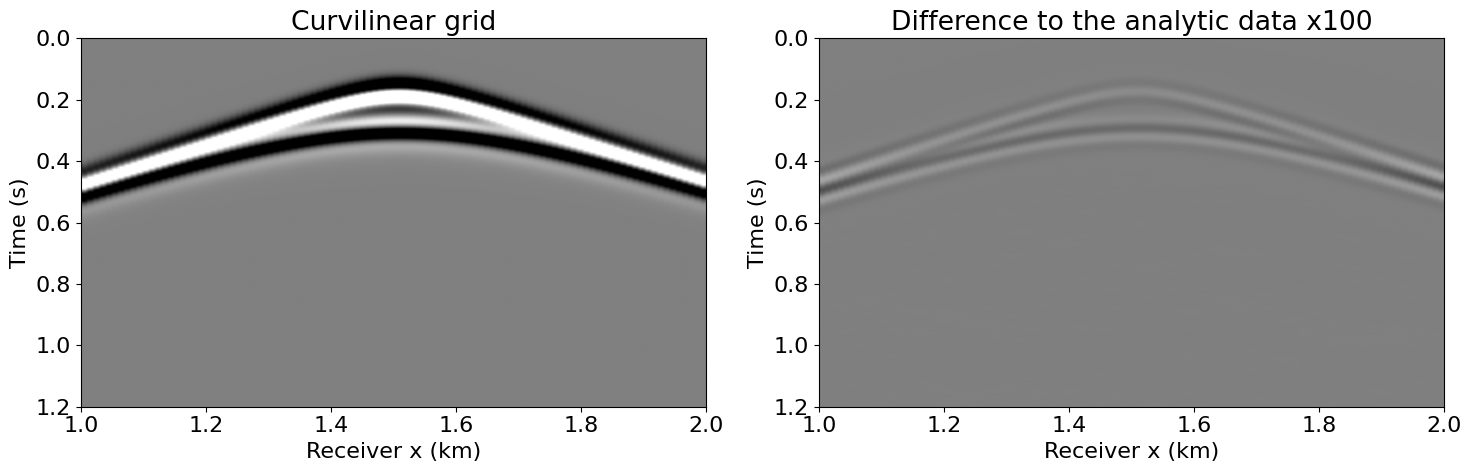

In [43]:
# NBVAL_IGNORE_OUTPUT
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
clip = np.abs(plane_analytic).max()/3
extent = [1., 2., tn, 0]
for ax, data, title in zip(axes, [plane_data, 100*(plane_data - plane_analytic)],
                           ['Curvilinear grid', 'Difference to the analytic data x100'],
                           strict=True):
    ax.imshow(data, aspect='auto', cmap='gray', vmin=-clip, vmax=clip, extent=extent)
    ax.set_xlabel('Receiver x (km)')
    ax.set_ylabel('Time (s)')
    ax.set_title(title)
plt.tight_layout()
plt.show()

The difference, magnified a hundred times, is of the order of a thousandth of the data. Repeating the run at 20 m and 5 m spacing shows how the misfit decreases with the grid spacing $h$ (this takes about a minute).

In [44]:
# NBVAL_IGNORE_OUTPUT
spacings = [20., 10., 5.]
misfits = [plane_misfit(plane_mapping, h)[0] for h in spacings]
orders = np.log2(np.array(misfits[:-1])/np.array(misfits[1:]))
print(f'misfits {np.round(misfits, 5)}, orders {orders.round(1)}')

Operator `Kernel` ran in 9.71 s


Operator `Kernel` ran in 36.90 s


Operator `Kernel` ran in 152.24 s


misfits [0.04377 0.00093 0.00023], orders [5.6 2. ]


In [45]:
assert misfits[1] < 2e-3

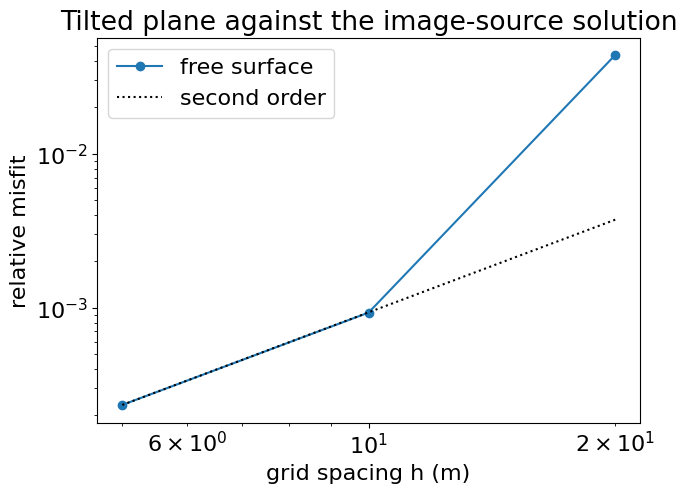

In [46]:
# NBVAL_IGNORE_OUTPUT
fig, ax = plt.subplots(figsize=(7, 5))
ax.loglog(spacings, misfits, 'o-', label='free surface')
ax.loglog(spacings, misfits[-1]*(np.array(spacings)/5.)**2, 'k:',
          label='second order')
ax.set_xlabel('grid spacing h (m)')
ax.set_ylabel('relative misfit')
ax.set_title('Tilted plane against the image-source solution')
ax.legend()
plt.show()

At 20 m the grid has only about three points per shortest wavelength and the run is poor. From 10 m down, the misfit decreases at close to second order, the order of the time stepping. At the 10 m spacing and time-step rule used for the hill, the data match the analytic solution to about $10^{-3}$. This bounds the error of the propagation and of the free surface over a slope; over the curved top of the hill the image is taken through the closest point of the surface, which this test does not exercise.

### The same plane with a custom map

`TerrainFollowing` covers topography, but other geometries need other maps. A map is a subclass of `CurvilinearMap` with two methods:

* `forward`, the physical coordinates of computational points, which must be smooth past the edges of the grid, where it places the halo nodes;
* `inverse`, the computational coordinates of physical points, used to place sparse functions and to find the images of the free surface.

The metric terms and the Jacobian are then computed by finite differences of `forward` (see the `CurvilinearMap` docstring for the optional closed forms). As an example, the plane can also be built by shearing the grid, shifting each column down by `slope*x` instead of stretching it, $z = \eta + 0.1\,\xi$:

In [47]:
class Shear(CurvilinearMap):

    def __init__(self, slope):
        self.slope = slope

    def forward(self, grid, computational):
        xi, eta = computational
        return xi, eta + self.slope*xi

    def inverse(self, grid, points):
        return np.stack([points[:, 0], points[:, 1] - self.slope*points[:, 0]],
                        axis=1)

In [48]:
# NBVAL_IGNORE_OUTPUT
shear_misfit = plane_misfit(Shear(slope), 10.)[0]
print(f'sheared plane: relative misfit {shear_misfit:.1e}')

Operator `Kernel` ran in 31.43 s


sheared plane: relative misfit 1.4e-03


In [49]:
assert shear_misfit < 2e-3

The sheared plane is less accurate than the stretched one. Its cells are not compressed under the plane, so its smallest cell is 10 m rather than 8 m and the time-step rule gives it a larger time step. With the same, smaller time step of 0.2 ms the two maps agree, and the misfit drops further: at the default time step the remaining error is mostly the time stepping.

In [50]:
# NBVAL_IGNORE_OUTPUT
maps = {'stretched': plane_mapping, 'sheared': Shear(slope)}
same_step = {name: plane_misfit(mapping, 10., dt=2e-4)[0]
             for name, mapping in maps.items()}
for name, value in same_step.items():
    print(f'{name} plane, dt = 0.2 ms: relative misfit {value:.1e}')

Operator `Kernel` ran in 97.85 s


Operator `Kernel` ran in 100.54 s


stretched plane, dt = 0.2 ms: relative misfit 1.3e-04
sheared plane, dt = 0.2 ms: relative misfit 1.2e-04


In [51]:
assert np.isclose(same_step['stretched'], same_step['sheared'], rtol=.1)
assert same_step['stretched'] < misfit

## 10. Seismic models

The models of the seismic examples build the grid themselves. With `fs=True` and a `surface`, `SeismicModel` builds it as a `CurvilinearGrid` with a `TerrainFollowing` map: the surface is given over the physical domain and continued flat across the absorbing layers, the grid extends `space_order` rows above it, into which the parameters are continued, and the critical time step follows the smallest cell.

In [52]:
from examples.seismic import SeismicModel

x_model = np.linspace(0., 3000., 301)
model = SeismicModel(origin=(0., 0.), spacing=(10., 10.), shape=(301, 151),
                     space_order=8, vp=1.5, nbl=40, fs=True,
                     surface=-elevation(x_model))
print(f'{type(model.grid).__name__}, shape {tuple(map(int, model.grid.shape))}, '
      f'vertical origin {float(model.grid.origin[-1]):.0f} m, '
      f'critical dt {model.critical_dt:.3f} ms')

Operator `initdamp` ran in 0.01 s


CurvilinearGrid, shape (381, 199), vertical origin -80 m, critical dt 3.460 ms


## Going further

* Everything in this notebook runs unchanged with MPI (`DEVITO_MPI=1 mpirun -n 4 python ...`): each rank builds the coordinates and metric terms of its own nodes, sparse functions are mapped onto the grid before being distributed, and the free surface equations run on the ranks that hold the surface.
* The same grid works in 3D, with a surface $s(x, y)$ and `Dimension`s `x`, `y`, `z`.
* The transpose `.T` of a physical derivative is its exact discrete transpose, for adjoint operators written with explicit transposes.
* The docstrings of `CurvilinearGrid`, `TerrainFollowing`, `CurvilinearMap`, `devito.resample`, `Derivative` (its `computational` argument) and the module `devito.passes.equations.reflection` describe every option.